# Pintar el lote real: de la regla por color a la etiqueta

En la clase 3 combinamos bandas para obtener una **señal** de vegetación. Hoy vamos a **pintar**: asignar a cada píxel una etiqueta (suelo, maíz o maleza). Ese mapa pintado se llama **máscara**.

Trabajamos siempre sobre una **imagen real**: una muestra del conjunto abierto WeedsGalore con maíz y malezas (600 × 600 píxeles, con bandas rojo, verde, azul, borde rojo e infrarrojo cercano). La etiqueta de referencia la hicieron personas que conocían el lote: 0 = fondo/suelo, 1 = maíz, 2 a 5 = malezas.

Vamos a comparar tres formas de pintar sobre la misma imagen real:

1. **Regla por color:** todo lo verde junto (como un NDVI con umbral).
2. **Agrupamiento automático (K-Means):** la máquina agrupa píxeles parecidos sin saber qué significan.
3. **Etiqueta de referencia:** la respuesta verificada en campo.

Solo la tercera sabe qué es maleza. Las otras dos agrupan apariencias.

## 1. La imagen real y su etiqueta

La muestra viene incluida en el repositorio, en `assets/geospatial/weedsgalore_muestra/` (sincronizala desde GitHub; no hay que descargar nada). La mostramos con un estiramiento simple por percentiles para verla bien, igual que en la clase 3. La etiqueta viene del trabajo de campo: nadie podría deducirla solo del color. La [ficha de fuente](../../assets/geospatial/weedsgalore_muestra_fuente.md) describe el origen y las bandas.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# La muestra viene con el repositorio: sincronizar desde GitHub, sin descargas
base = Path("../../assets/geospatial/weedsgalore_muestra")
if not base.exists():
    base = Path("assets/geospatial/weedsgalore_muestra")
nombre = "2023-06-06_0625"
bandas = {}
for banda, sufijo in [("rojo", "R"), ("verde", "G"), ("azul", "B"), ("borde_rojo", "RE"), ("nir", "NIR")]:
    bandas[banda] = np.asarray(Image.open(base / "images" / f"{nombre}_{sufijo}.png"), dtype=np.float32)
etiqueta = np.asarray(Image.open(base / "semantics" / f"{nombre}.png"))
identificador, fecha = nombre, "2023-06-06"
print(f"Muestra {identificador} · {fecha} · {etiqueta.shape[1]} × {etiqueta.shape[0]} píxeles")

def estirar(banda):
    baja, alta = np.percentile(banda, (2, 98))
    return np.clip((banda - baja) / (alta - baja + 1e-6), 0, 1)

rgb = np.dstack((estirar(bandas["rojo"]), estirar(bandas["verde"]), estirar(bandas["azul"])))
foto = (rgb * 255).astype(np.uint8)

print(f"Fondo/suelo: {(etiqueta == 0).sum():,} · maíz: {(etiqueta == 1).sum():,} · malezas: {(etiqueta > 1).sum():,}")
print(f"Bandas: {sorted(bandas)}")

Muestra 2023-06-06_0625 · 2023-06-06 · 600 × 600 píxeles
Fondo/suelo: 298,883 · maíz: 24,135 · malezas: 36,982
Bandas: ['azul', 'borde_rojo', 'nir', 'rojo', 'verde']


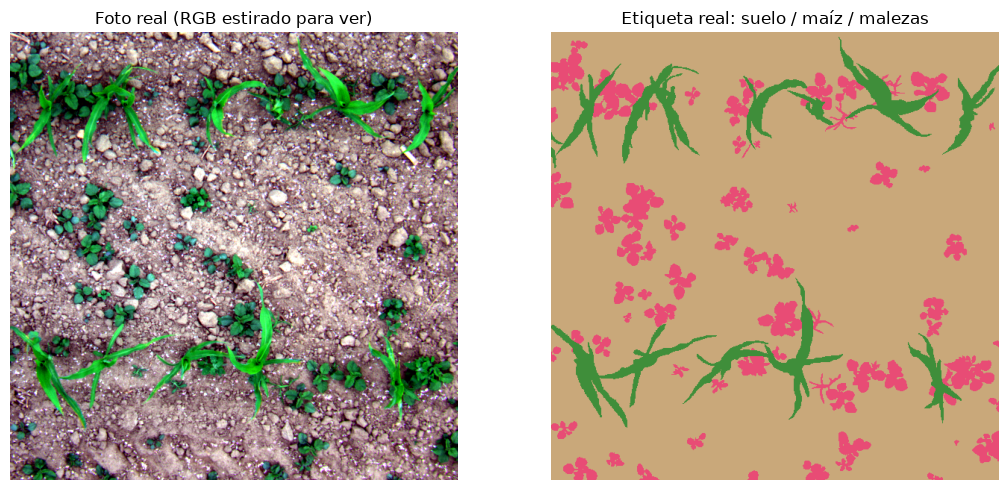

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(rgb)
axes[0].set_title("Foto real (RGB estirado para ver)")
axes[0].axis("off")

ref_vis = np.zeros(etiqueta.shape + (3,), dtype=float)
ref_vis[etiqueta == 0] = [0.79, 0.66, 0.48]
ref_vis[etiqueta == 1] = [0.25, 0.56, 0.23]
ref_vis[etiqueta > 1] = [0.91, 0.30, 0.46]
axes[1].imshow(ref_vis)
axes[1].set_title("Etiqueta real: suelo / maíz / malezas")
axes[1].axis("off")
plt.tight_layout()
plt.show()

La etiqueta de la derecha es **la respuesta verificada en campo**. La definieron personas que sabían qué se sembró y qué sobra en ese lote. En una imagen real, el maíz y las malezas se ven parecidos: el color no trae el nombre de cada planta.

## 2. Regla por color sobre la imagen real: todo lo verde junto

La regla más simple: exceso de verde (ExG = 2·verde − rojo − azul) por encima de un umbral. Es la misma idea que un umbral sobre NDVI: **separa verde de no-verde**, pero no distingue maíz de maleza.

In [4]:
r = bandas["rojo"].astype(float)
g = bandas["verde"].astype(float)
b = bandas["azul"].astype(float)
exg = 2 * g - r - b
umbral = float(np.percentile(exg, 60))
regla_verde = exg > umbral
print(f"Umbral ExG (percentil 60): {umbral:,.0f}")
print(f"Píxeles pintados por la regla: {regla_verde.sum():,} de {regla_verde.size:,}")
print(f"Píxeles reales de planta (maíz + malezas): {((etiqueta == 1) | (etiqueta > 1)).sum():,}")
print(f"De lo pintado, cae en planta real: {(regla_verde & (etiqueta > 0)).sum() / regla_verde.sum() * 100:.1f}%")

Umbral ExG (percentil 60): 3,392
Píxeles pintados por la regla: 143,714 de 360,000
Píxeles reales de planta (maíz + malezas): 61,117
De lo pintado, cae en planta real: 39.9%


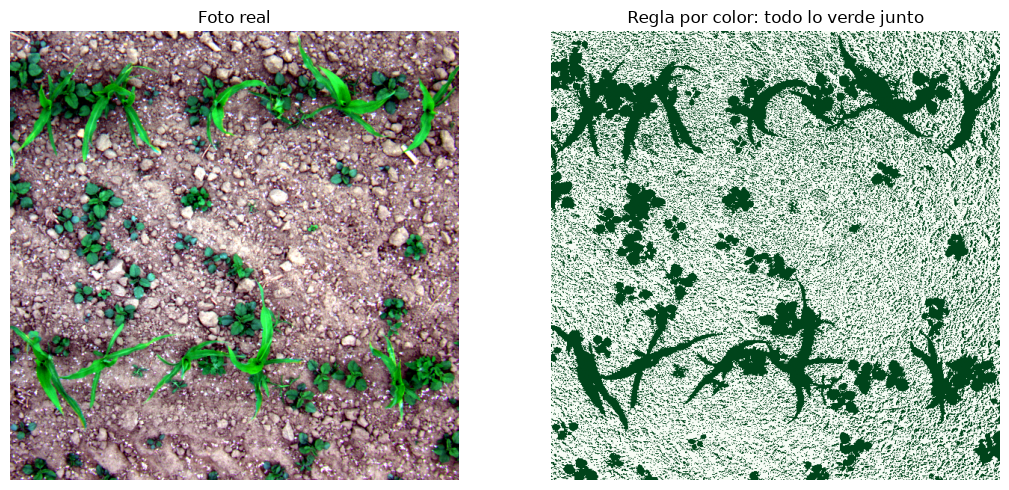

La regla recupera el 95.7% del maíz
y el 92.5% de las malezas: las mezcla en un solo grupo


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(rgb)
axes[0].set_title("Foto real")
axes[0].axis("off")
axes[1].imshow(regla_verde, cmap="Greens")
axes[1].set_title("Regla por color: todo lo verde junto")
axes[1].axis("off")
plt.tight_layout()
plt.show()
print(f"La regla recupera el {(regla_verde & (etiqueta == 1)).sum() / (etiqueta == 1).sum() * 100:.1f}% del maíz")
print(f"y el {(regla_verde & (etiqueta > 1)).sum() / (etiqueta > 1).sum() * 100:.1f}% de las malezas: las mezcla en un solo grupo")

**Ejercicio 1.** Mirá el panel derecho y respondé: ¿la regla separó el maíz de la maleza? ¿Qué información le falta a la regla para saber cuál verde sobra?

La regla encuentra vegetación, pero **mezcla** maíz y maleza en un solo grupo. Para separarlas haría falta saber qué se sembró, algo que el color no contiene.

## 3. Agrupamiento automático (K-Means) sobre la imagen real: agrupa sin saber

K-Means agrupa píxeles de colores parecidos en K grupos. Funciona así: elige K colores promedio, asigna cada píxel al más cercano y repite hasta que los grupos se estabilizan. No recibe etiquetas: **inventa los grupos** a partir de las apariencias. Píxeles parecidos quedan juntos, pero el grupo no tiene nombre agronómico: nadie le dijo qué es maíz o maleza.

Para que corra rápido en clase, lo aplicamos sobre una versión reducida de la imagen real.

In [6]:
from sklearn.cluster import KMeans
from PIL import Image

# Versión reducida para que el agrupamiento corra rápido en clase
chica = np.asarray(Image.fromarray(foto).resize((150, 150), Image.BILINEAR)).reshape(-1, 3)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=7)
grupos_chicos = kmeans.fit_predict(chica).reshape(150, 150)
grupos = np.asarray(Image.fromarray(grupos_chicos.astype(np.uint8), mode="L").resize(
    (etiqueta.shape[1], etiqueta.shape[0]), Image.NEAREST))
print("Grupos encontrados:", sorted(np.unique(grupos).tolist()))
for g in sorted(np.unique(grupos)):
    print(f"Grupo {g}: {(grupos == g).sum():,} píxeles")

Grupos encontrados: [0, 1, 2]
Grupo 0: 156,128 píxeles
Grupo 1: 83,552 píxeles
Grupo 2: 120,320 píxeles


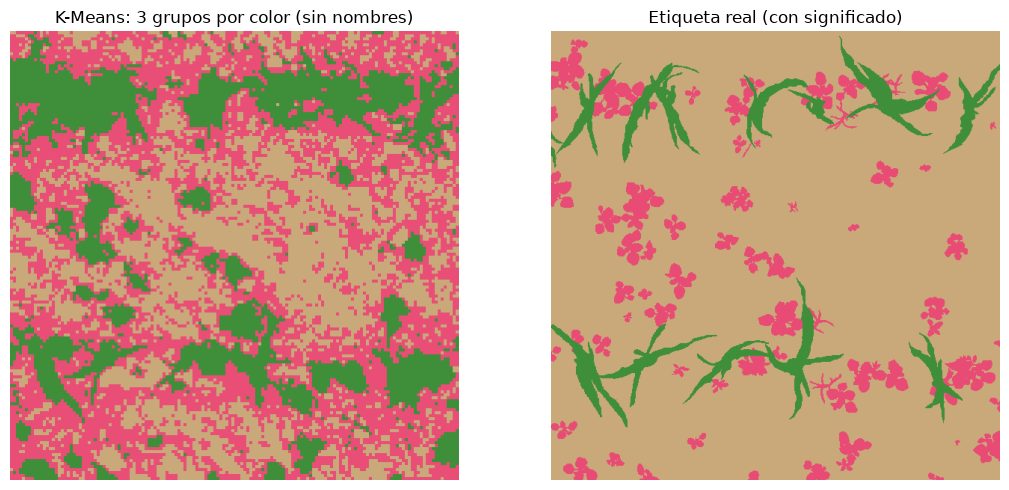

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
colores_k = np.array([[233, 78, 119], [63, 143, 58], [201, 169, 122]])
axes[0].imshow(colores_k[grupos % 3])
axes[0].set_title("K-Means: 3 grupos por color (sin nombres)")
axes[0].axis("off")
axes[1].imshow(ref_vis)
axes[1].set_title("Etiqueta real (con significado)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

**Ejercicio 2.** Compará los dos paneles: ¿los grupos de K-Means coinciden con suelo, maíz y maleza? ¿Qué pasaría si el maíz y la maleza tuvieran exactamente el mismo verde?

K-Means separa apariencias, no significados. Si dos plantas se ven igual, quedan en el mismo grupo aunque una sea maíz y la otra maleza. Por eso el agrupamiento **no identifica malezas**: solo ordena píxeles por parecido.

## 4. Pintar a mano sobre la imagen real: así se hace una máscara

Ahora te toca etiquetar sobre la foto real. Tomamos un recorte de 60 × 60 píxeles que contiene maíz, maleza y suelo. Decidí píxel por píxel qué es maleza. Este es el trabajo que hacen las personas antes de entrenar un modelo: **pintar ejemplos**.

Recorte de 60 × 60 píxeles
Maíz: 858 · maleza: 1,058 · fondo: 1,684


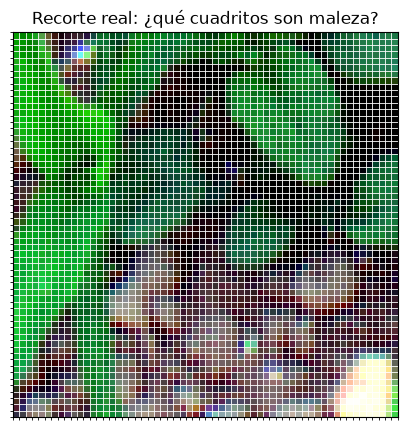

In [8]:
# Recorte real de 60 × 60 con maíz, maleza y suelo
y0, y1, x0, x1 = 80, 140, 40, 100
recorte = foto[y0:y1, x0:x1]
ref_recorte = etiqueta[y0:y1, x0:x1]
print(f"Recorte de {recorte.shape[1]} × {recorte.shape[0]} píxeles")
print(f"Maíz: {(ref_recorte == 1).sum():,} · maleza: {(ref_recorte > 1).sum():,} · fondo: {(ref_recorte == 0).sum():,}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(recorte)
ax.set_xticks(np.arange(-0.5, recorte.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, recorte.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.6)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Recorte real: ¿qué cuadritos son maleza?")
plt.show()

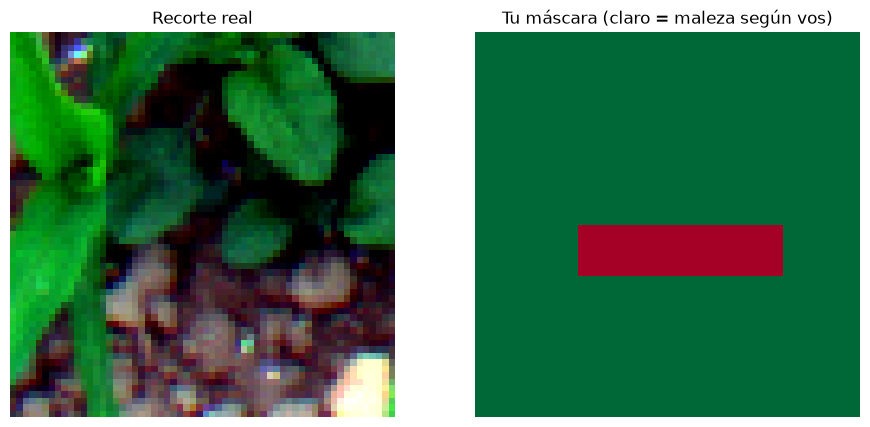

Pintaste 256 píxeles como maleza


In [18]:
# TU TURNO: marcá con 1 los píxeles que consideres maleza (el resto queda en 0).
# Usá filas y columnas del recorte. Ejemplo: mi_mascara[3, 5] = 1
mi_mascara = np.zeros((y1 - y0, x1 - x0), dtype=int)

# --- Pintá acá abajo (ejemplo inicial sobre una zona densa en maleza) ---
mi_mascara[30:38, 16:48] = 1
# --- Fin de tu edición ---

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(recorte)
axes[0].set_title("Recorte real")
axes[0].axis("off")
axes[1].imshow(mi_mascara, cmap="RdYlGn_r", vmin=0, vmax=1)
axes[1].set_title("Tu máscara (claro = maleza según vos)")
axes[1].axis("off")
plt.show()
print(f"Pintaste {mi_mascara.sum():,} píxeles como maleza")

Coincidencias: 108 · Pintaste de más: 148 · Te faltaron: 950


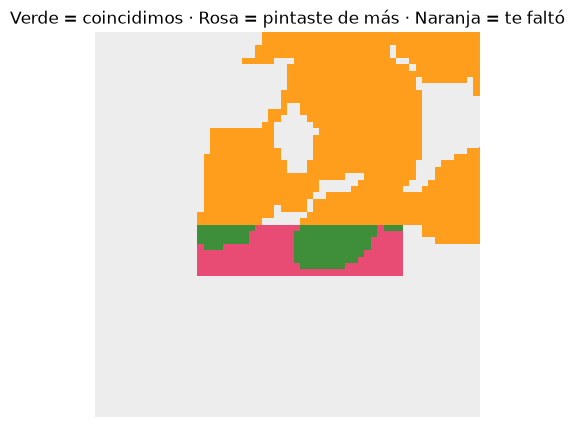

In [19]:
# Comparamos tu máscara con la referencia real de campo
ref_maleza = (ref_recorte > 1).astype(int)
aciertos = ((mi_mascara == 1) & (ref_maleza == 1)).sum()
sobrantes = ((mi_mascara == 1) & (ref_maleza == 0)).sum()
faltantes = ((mi_mascara == 0) & (ref_maleza == 1)).sum()
print(f"Coincidencias: {aciertos} · Pintaste de más: {sobrantes} · Te faltaron: {faltantes}")

fig, ax = plt.subplots(figsize=(7, 5))
comparar = np.zeros(mi_mascara.shape + (3,), dtype=float)
comparar[:, :] = [0.93, 0.93, 0.93]
comparar[(mi_mascara == 1) & (ref_maleza == 1)] = [0.25, 0.56, 0.23]  # bien: verde
comparar[(mi_mascara == 1) & (ref_maleza == 0)] = [0.91, 0.30, 0.46]  # de más: rosa
comparar[(mi_mascara == 0) & (ref_maleza == 1)] = [1.0, 0.62, 0.11]  # faltó: naranja
ax.imshow(comparar)
ax.set_title("Verde = coincidimos · Rosa = pintaste de más · Naranja = te faltó")
ax.axis("off")
plt.show()

**Ejercicio 3.** Probá pintar de nuevo incluyendo o sacando los píxeles del borde de las hojas. ¿Cambia el resultado? En una foto real los bordes son difusos: dos personas pintan distinto y el modelo aprende con esa duda incluida.

## 5. Semántica vs. por instancia, sobre la imagen real

La etiqueta semántica pinta **toda la maleza del mismo color**. La versión por instancia le da **un número a cada planta conectada**. La pregunta cambia: ¿cuánta superficie o cuántas plantas?

Grupos de maleza conectados: 81
Superficie con maleza: 36,982 píxeles · con maíz: 24,135


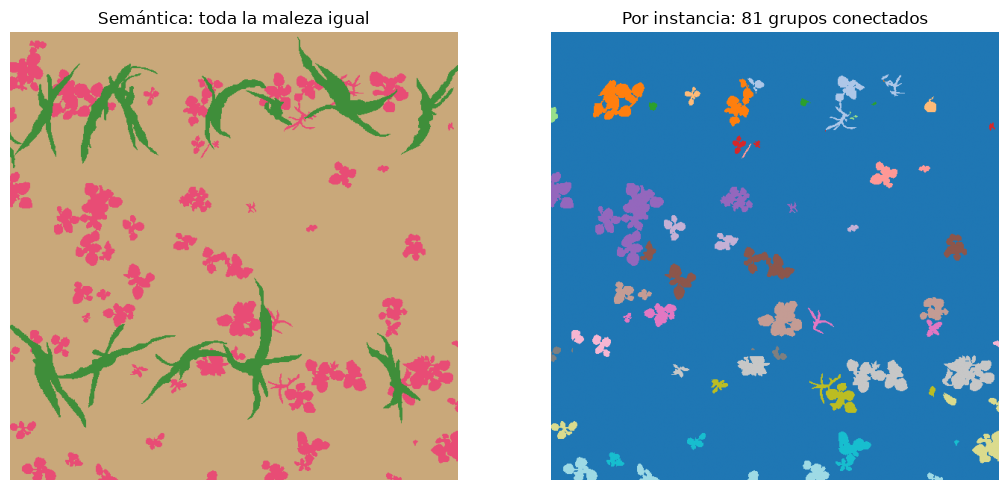

Ojo: si dos plantas se tocan, quedan como un solo grupo conectado.


In [11]:
from scipy import ndimage

instancias, n_plantas = ndimage.label(etiqueta > 1)
print(f"Grupos de maleza conectados: {n_plantas}")
print(f"Superficie con maleza: {(etiqueta > 1).sum():,} píxeles · con maíz: {(etiqueta == 1).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(ref_vis)
axes[0].set_title("Semántica: toda la maleza igual")
axes[0].axis("off")
axes[1].imshow(instancias, cmap="tab20")
axes[1].set_title(f"Por instancia: {n_plantas} grupos conectados")
axes[1].axis("off")
plt.tight_layout()
plt.show()
print("Ojo: si dos plantas se tocan, quedan como un solo grupo conectado.")

Si el pedido es medir superficie, alcanza con la semántica. Si el pedido es contar plantas o visitar cada una, hace falta la versión por instancia. **El mapa depende de la decisión** que hay que tomar en el campo. Y en una imagen real, separar plantas que se tocan ya es parte de la dificultad.

## 6. Cierre: qué necesita un modelo para aprender

Todo lo anterior fue sobre esta imagen real. La regla por color pinta vegetación; la etiqueta real separa maíz de malezas porque alguien fue al campo y lo verificó. Un modelo como U-Net aprendería a **copiar** esas etiquetas en fotos nuevas; uno como Mask R-CNN aprendería además a **separar cada planta**. Sin etiquetas, ninguno de los dos puede saber qué verde sobra.

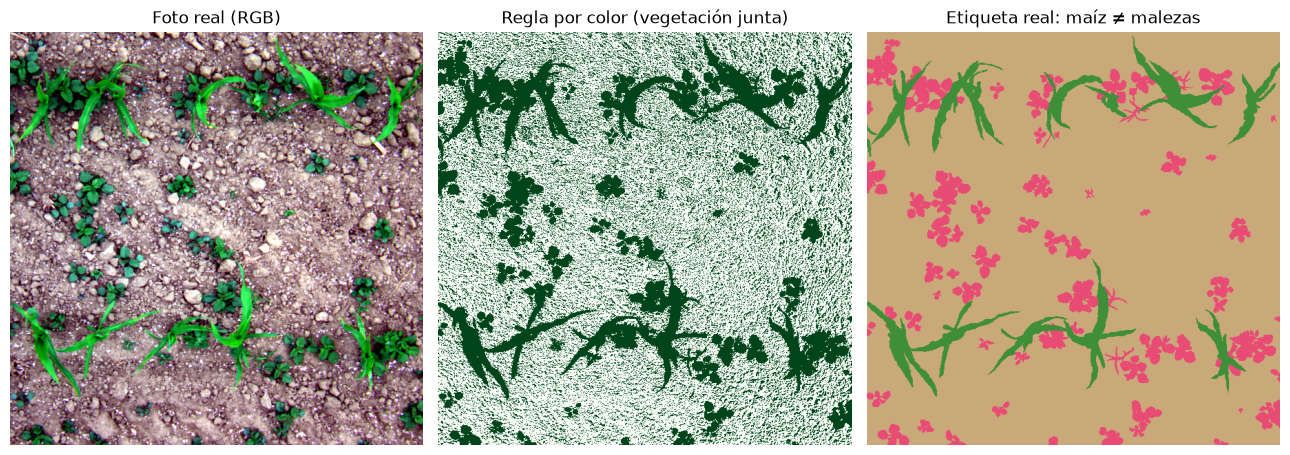

Regla pinta 143,714 píxeles · maleza real: 36,982 · maíz: 24,135
La regla mezcla las dos clases: por eso no identifica malezas.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
axes[0].imshow(rgb)
axes[0].set_title("Foto real (RGB)")
axes[0].axis("off")
axes[1].imshow(regla_verde, cmap="Greens")
axes[1].set_title("Regla por color (vegetación junta)")
axes[1].axis("off")
axes[2].imshow(ref_vis)
axes[2].set_title("Etiqueta real: maíz ≠ malezas")
axes[2].axis("off")
plt.tight_layout()
plt.show()
print(f"Regla pinta {regla_verde.sum():,} píxeles · maleza real: {(etiqueta > 1).sum():,} · maíz: {(etiqueta == 1).sum():,}")
print("La regla mezcla las dos clases: por eso no identifica malezas.")

**Para cerrar.** Todo el notebook trabajó sobre la misma imagen real. La diferencia entre la regla y la etiqueta no es el color: es el **conocimiento del lote**. En la clase 5 veremos cómo medir si un modelo pinta bien: cuánto coincide con la referencia, qué se le escapa y qué pinta de más.